In [1]:

from pathlib import Path
import pandas as pd
import numpy as np

# Project paths
PROJECT_ROOT = Path.cwd().parent if Path.cwd().name == "notebooks" else Path.cwd()

DATA_PATH = (
    PROJECT_ROOT
    / "data"
    / "raw"
    / "archive-3"
    / "city_day.csv"
)

PROCESSED_DIR = PROJECT_ROOT / "data" / "processed"
PROCESSED_DIR.mkdir(parents=True, exist_ok=True)

# Load the original dataset
df = pd.read_csv(DATA_PATH)

# Parse dates
df["Date"] = pd.to_datetime(df["Date"], errors="coerce")

print("Dataset loaded successfully")
print("Shape:", df.shape)
print("Duplicate rows:", df.duplicated().sum())
print("Missing dates:", df["Date"].isna().sum())
print("Duplicate city-date pairs:",
      df.duplicated(subset=["City", "Date"]).sum())

display(df.head())
display(df.dtypes.to_frame("Data Type"))


Dataset loaded successfully
Shape: (29531, 16)
Duplicate rows: 0
Missing dates: 0
Duplicate city-date pairs: 0


,City,Date,PM2.5,PM10,NO,NO2,NOx,NH3,CO,SO2,O3,Benzene,Toluene,Xylene,AQI,AQI_Bucket
0,Ahmedabad,2015-01-01,NaN,NaN,0.92,18.22,17.15,NaN,0.92,27.64,133.36,0.00,0.02,0.00,NaN,NaN
1,Ahmedabad,2015-01-02,NaN,NaN,0.97,15.69,16.46,NaN,0.97,24.55,34.06,3.68,5.50,3.77,NaN,NaN
2,Ahmedabad,2015-01-03,NaN,NaN,17.40,19.30,29.70,NaN,17.40,29.07,30.70,6.80,16.40,2.25,NaN,NaN
3,Ahmedabad,2015-01-04,NaN,NaN,1.70,18.48,17.97,NaN,1.70,18.59,36.08,4.43,10.14,1.00,NaN,NaN
4,Ahmedabad,2015-01-05,NaN,NaN,22.10,21.42,37.76,NaN,22.10,39.33,39.31,7.01,18.89,2.78,NaN,NaN


,Data Type
City,str
Date,datetime64[us]
PM2.5,float64
PM10,float64
NO,float64
NO2,float64
NOx,float64
NH3,float64
CO,float64
SO2,float64


In [2]:
from pathlib import Path
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

PROJECT_ROOT = Path.cwd().parent if Path.cwd().name == "notebooks" else Path.cwd()

DATA_PATH = PROJECT_ROOT / "data" / "raw" / "archive-3" / "city_day.csv"
PROCESSED_DIR = PROJECT_ROOT / "data" / "processed"
FIGURES_DIR = PROJECT_ROOT / "outputs" / "figures"
TABLES_DIR = PROJECT_ROOT / "outputs" / "tables"

PROCESSED_DIR.mkdir(parents=True, exist_ok=True)
FIGURES_DIR.mkdir(parents=True, exist_ok=True)
TABLES_DIR.mkdir(parents=True, exist_ok=True)

df = pd.read_csv(DATA_PATH)
df["Date"] = pd.to_datetime(df["Date"], errors="coerce")

print("Dataset loaded successfully")
print("Shape:", df.shape)
print("Missing values:", df.isna().sum().sum())

Dataset loaded successfully
Shape: (29531, 16)
Missing values: 88488


In [3]:
missing_report = pd.DataFrame({
    "Missing_Count": df.isna().sum(),
    "Missing_Percent": (df.isna().mean() * 100).round(2),
    "Data_Type": df.dtypes.astype(str)
})

missing_report = missing_report.sort_values(
    "Missing_Percent",
    ascending=False
)

display(missing_report)

missing_report.to_csv(
    TABLES_DIR / "missing_values_before_cleaning.csv"
)

,Missing_Count,Missing_Percent,Data_Type
Xylene,18109,61.32,float64
PM10,11140,37.72,float64
NH3,10328,34.97,float64
Toluene,8041,27.23,float64
Benzene,5623,19.04,float64
AQI,4681,15.85,float64
AQI_Bucket,4681,15.85,str
PM2.5,4598,15.57,float64
NOx,4185,14.17,float64
O3,4022,13.62,float64


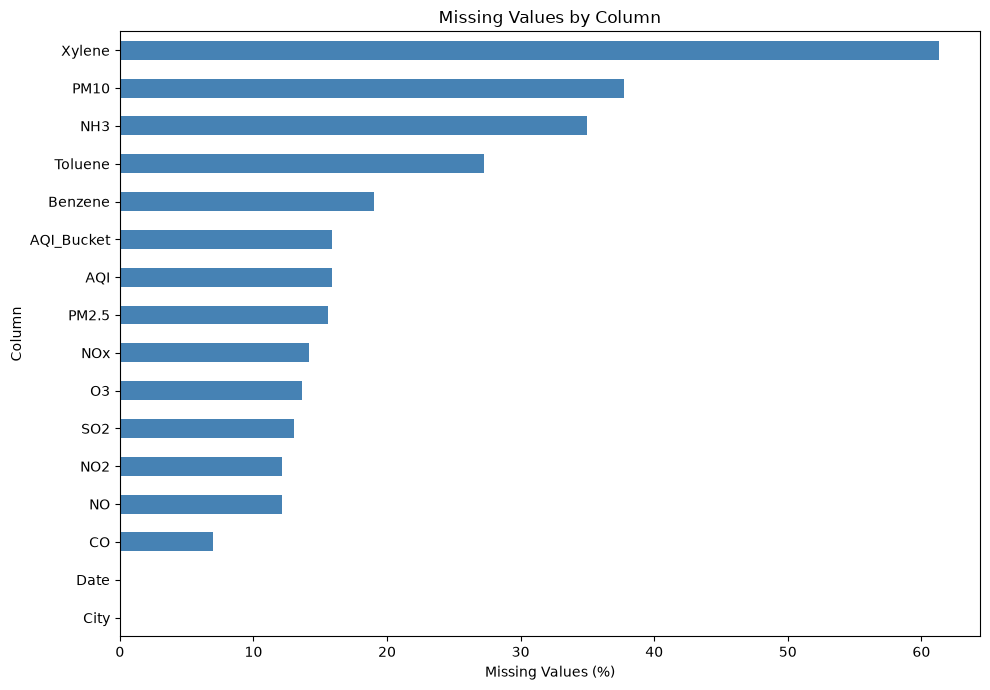

In [4]:
missing_percent = (
    df.isna().mean().mul(100)
    .sort_values(ascending=True)
)

plt.figure(figsize=(10, 7))

missing_percent.plot(
    kind="barh",
    color="steelblue"
)

plt.title("Missing Values by Column")
plt.xlabel("Missing Values (%)")
plt.ylabel("Column")
plt.tight_layout()

plt.savefig(
    FIGURES_DIR / "missing_values_before_cleaning.png",
    dpi=300,
    bbox_inches="tight"
)

plt.show()

In [5]:
print("Exact duplicate rows:", df.duplicated().sum())

print(
    "Duplicate city-date pairs:",
    df.duplicated(subset=["City", "Date"]).sum()
)

print("Missing city values:", df["City"].isna().sum())
print("Missing date values:", df["Date"].isna().sum())

print("\nDate range:")
print("Start:", df["Date"].min())
print("End:", df["Date"].max())

Exact duplicate rows: 0
Duplicate city-date pairs: 0
Missing city values: 0
Missing date values: 0

Date range:
Start: 2015-01-01 00:00:00
End: 2020-07-01 00:00:00


,count,mean,std,min,25%,50%,75%,max
PM2.5,24933.0,67.45,64.66,0.04,28.82,48.57,80.59,949.99
PM10,18391.0,118.13,90.61,0.01,56.26,95.68,149.74,1000.00
NO,25949.0,17.57,22.79,0.02,5.63,9.89,19.95,390.68
NO2,25946.0,28.56,24.47,0.01,11.75,21.69,37.62,362.21
NOx,25346.0,32.31,31.65,0.00,12.82,23.52,40.13,467.63
NH3,19203.0,23.48,25.68,0.01,8.58,15.85,30.02,352.89
CO,27472.0,2.25,6.96,0.00,0.51,0.89,1.45,175.81
SO2,25677.0,14.53,18.13,0.01,5.67,9.16,15.22,193.86
O3,25509.0,34.49,21.69,0.01,18.86,30.84,45.57,257.73
Benzene,23908.0,3.28,15.81,0.00,0.12,1.07,3.08,455.03


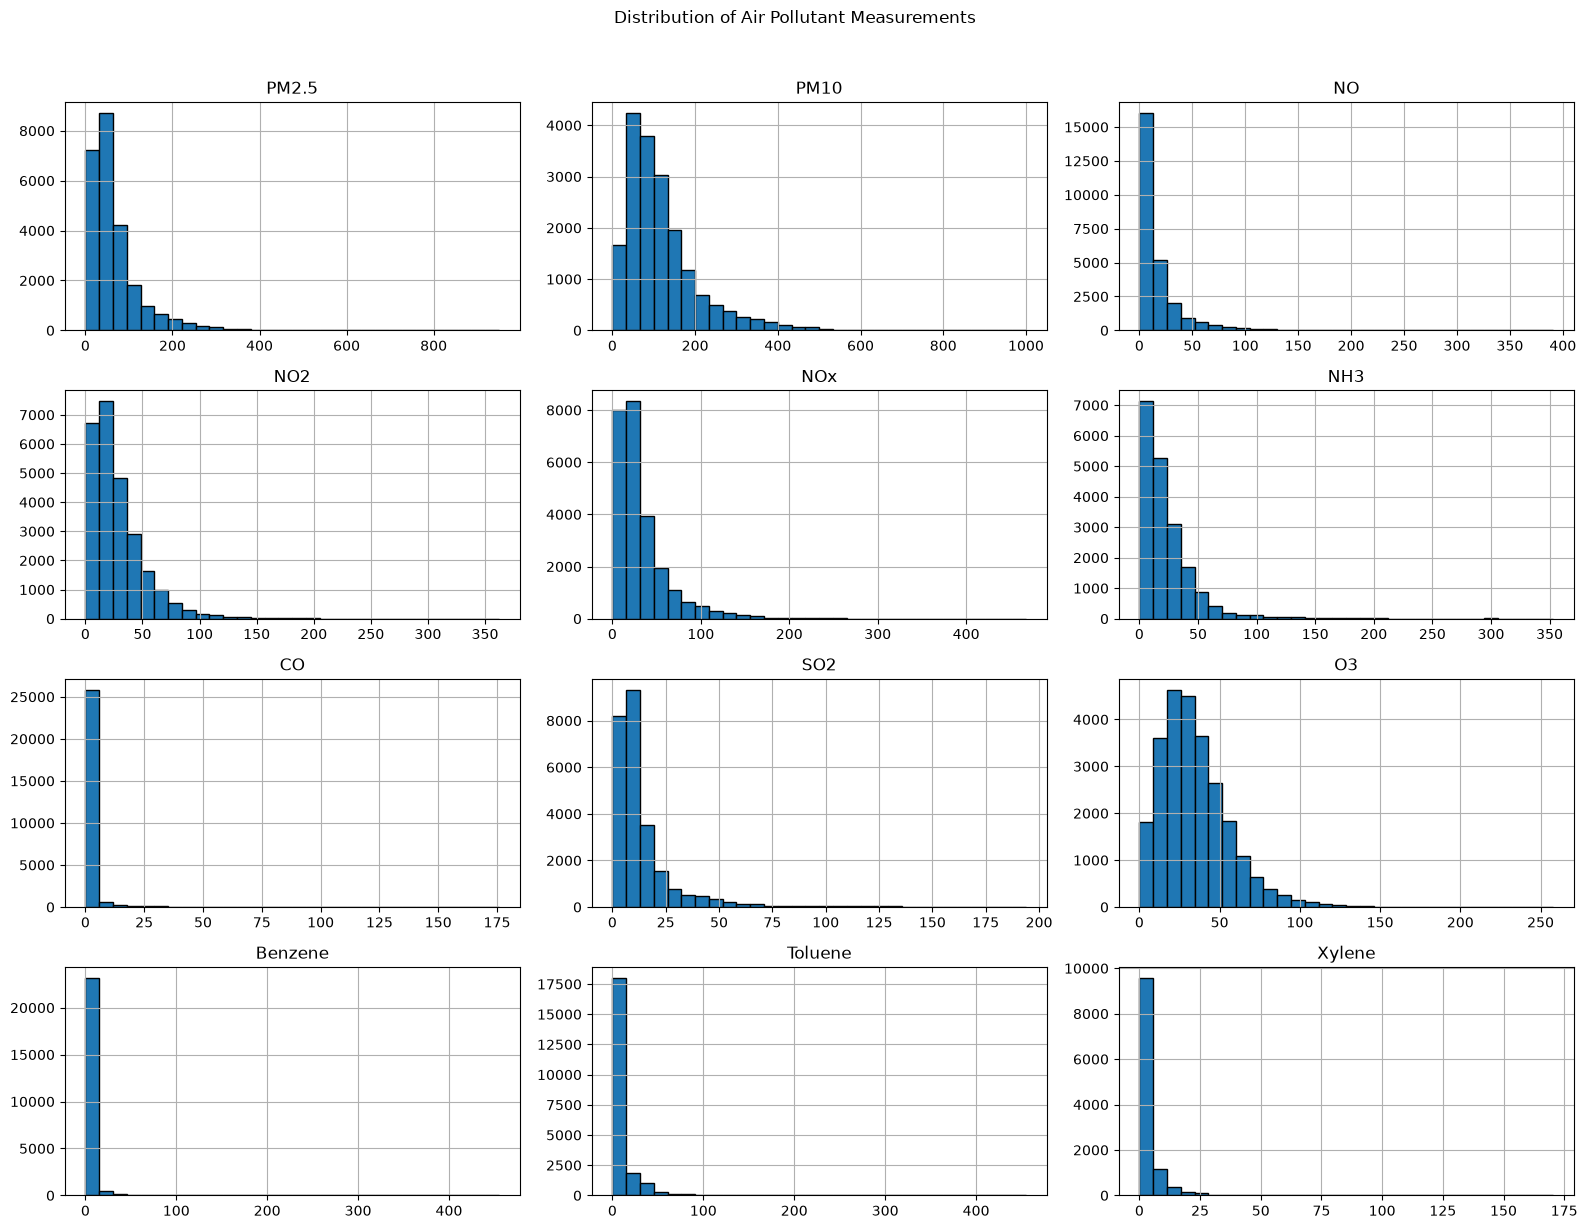

In [6]:
pollutant_cols = [
    "PM2.5", "PM10", "NO", "NO2", "NOx",
    "NH3", "CO", "SO2", "O3",
    "Benzene", "Toluene", "Xylene"
]

pollutant_cols = [
    col for col in pollutant_cols
    if col in df.columns
]

display(df[pollutant_cols].describe().T.round(2))

df[pollutant_cols].hist(
    figsize=(16, 12),
    bins=30,
    edgecolor="black"
)

plt.suptitle(
    "Distribution of Air Pollutant Measurements",
    y=1.02
)

plt.tight_layout()
plt.show()

In [7]:
df_clean = df.copy()

# Keep a record of missingness before imputation.
missing_before = df_clean.isna().sum()

# Impute pollutant values using city-specific medians.
for col in pollutant_cols:
    city_medians = df_clean.groupby("City")[col].transform("median")

    df_clean[col] = df_clean[col].fillna(city_medians)

    # Fallback when a city has no available values.
    df_clean[col] = df_clean[col].fillna(
        df_clean[col].median()
    )

print("Missing values before cleaning:", missing_before.sum())
print("Missing values after pollutant imputation:",
      df_clean[pollutant_cols].isna().sum().sum())

display(
    df_clean[pollutant_cols].isna().sum()
    .to_frame("Remaining_Missing")
)

Missing values before cleaning: 88488
Missing values after pollutant imputation: 0


,Remaining_Missing
PM2.5,0
PM10,0
NO,0
NO2,0
NOx,0
NH3,0
CO,0
SO2,0
O3,0
Benzene,0


In [8]:
print(
    "AQI missing before cleaning:",
    df["AQI"].isna().sum()
)

print(
    "AQI missing after pollutant imputation:",
    df_clean["AQI"].isna().sum()
)

print(
    "AQI missing percentage:",
    round(df_clean["AQI"].isna().mean() * 100, 2),
    "%"
)

display(
    df_clean.groupby("City").agg(
        Total_Records=("AQI", "size"),
        Available_AQI=("AQI", "count"),
        Median_AQI=("AQI", "median")
    ).sort_values("Available_AQI")
)

AQI missing before cleaning: 4681
AQI missing after pollutant imputation: 4681
AQI missing percentage: 15.85 %


,Total_Records,Available_AQI,Median_AQI
City,,,
Aizawl,113,111,23.0
Ernakulam,162,153,94.0
Kochi,162,158,99.0
Shillong,310,205,48.0
Bhopal,289,278,120.0
Chandigarh,304,299,82.0
Coimbatore,386,344,75.0
Guwahati,502,495,98.0
Talcher,925,698,128.5


In [9]:
output_path = PROCESSED_DIR / "city_day_cleaned.csv"

df_clean.to_csv(output_path, index=False)

print("Cleaned dataset saved to:", output_path)
print("Final shape:", df_clean.shape)
print("Exact duplicate rows:", df_clean.duplicated().sum())

Cleaned dataset saved to: /Users/ashokreddy/india-air-pollution-analysis/data/processed/city_day_cleaned.csv
Final shape: (29531, 16)
Exact duplicate rows: 0


In [10]:
missing_after = df_clean.isna().sum()

cleaning_report = pd.DataFrame({
    "Missing_Before": missing_before,
    "Missing_After": missing_after,
    "Missing_Before_Percent": (
        missing_before / len(df) * 100
    ).round(2),
    "Missing_After_Percent": (
        missing_after / len(df_clean) * 100
    ).round(2)
})

display(cleaning_report)

cleaning_report.to_csv(
    TABLES_DIR / "data_cleaning_report.csv"
)

print("Cleaning report exported successfully.")

,Missing_Before,Missing_After,Missing_Before_Percent,Missing_After_Percent
City,0,0,0.00,0.00
Date,0,0,0.00,0.00
PM2.5,4598,0,15.57,0.00
PM10,11140,0,37.72,0.00
NO,3582,0,12.13,0.00
NO2,3585,0,12.14,0.00
NOx,4185,0,14.17,0.00
NH3,10328,0,34.97,0.00
CO,2059,0,6.97,0.00
SO2,3854,0,13.05,0.00


Cleaning report exported successfully.
